# 03 - Fusion, evaluation and Raspberry Pi export

Both branches are now **frozen**. Only the fusion head is trained, on

    concat[ image_embedding (128) | sensor_embedding (64) | image RSL | sensor RSL ]

Appending each branch's own scalar prediction matters: it gives the head a ready-made
baseline, so fusing can refine the stronger branch instead of having to relearn it.

In [1]:
import sys, warnings
sys.path.insert(0, "../scripts")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
import common as C, datasets as D, models as M
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__)

2026-09-06 18:40:45.768525: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-06 18:40:45.809421: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-09-06 18:40:47.206552: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.20.0


In [2]:
df, X, F, y, (tr, va, te) = D.load_all("blocked", "full")
sensor = tf.keras.models.load_model(C.MODELS / "sensor_model_blocked_full.keras", compile=False)
image  = tf.keras.models.load_model(C.MODELS / "image_head_blocked_full.keras", compile=False)
sensor.trainable = False
image.trainable = False

def embed(model, layer, A):
    return tf.keras.Model(model.input, model.get_layer(layer).output).predict(A, verbose=0)

E = np.concatenate([
    embed(image, "image_embedding", F),
    embed(sensor, "sensor_embedding", X),
    image.predict(F, verbose=0),
    sensor.predict(X, verbose=0),
], axis=1).astype("float32")
print("fusion input:", E.shape)

fusion input: (3067, 194)


In [3]:
C.set_seeds()
fusion = M.compile_regressor(M.build_fusion_head())
fusion.summary()
history = fusion.fit(E[tr], y[tr], validation_data=(E[va], y[va]),
                     epochs=200, batch_size=64, callbacks=M.default_callbacks(), verbose=0)
print(f"stopped after {len(history.history['loss'])} epochs")

Model: "fusion_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fused_embedding (InputLayer)    │ (None, 194)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fusion_dense_1 (Dense)          │ (None, 64)             │        12,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fusion_bn_1                     │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fusion_drop_1 (Dropout)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fusion_dense_2 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ remaining_shelf_life (Dense)    │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849 (58.00 KB)

 Trainable params: 14,721 (57.50 KB)

 Non-trainable params: 128 (512.00 B)

stopped after 47 epochs


## 1. Does fusing actually help?

,MAE,RMSE,R2,WithinHalfDay,WithinOneDay
Sensor only,0.7535,1.3876,0.4431,0.4502,0.8339
Image only,0.2424,0.4371,0.9448,0.8708,0.9631
Fusion,0.3032,0.5236,0.9207,0.8672,0.9594


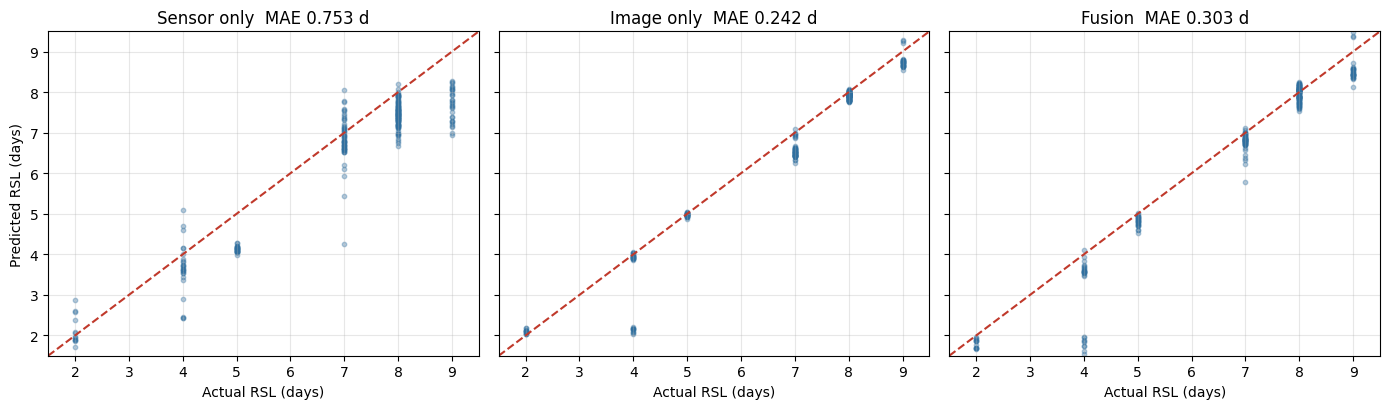

In [4]:
rows = {
    "Sensor only": sensor.predict(X[te], verbose=0).ravel(),
    "Image only":  image.predict(F[te], verbose=0).ravel(),
    "Fusion":      fusion.predict(E[te], verbose=0).ravel(),
}
table = pd.DataFrame({k: C.regression_metrics(y[te], v) for k, v in rows.items()}).T
display(table[["MAE", "RMSE", "R2", "WithinHalfDay", "WithinOneDay"]].round(4))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
lims = [y[te].min()-.5, y[te].max()+.5]
for a, (name, p) in zip(ax, rows.items()):
    a.scatter(y[te], p, s=10, alpha=.35, color="#2f6f9f")
    a.plot(lims, lims, "--", color="#c0392b"); a.set_xlim(lims); a.set_ylim(lims)
    a.set_title(f"{name}  MAE {C.regression_metrics(y[te], p)['MAE']:.3f} d")
    a.set_xlabel("Actual RSL (days)"); a.grid(alpha=.3)
ax[0].set_ylabel("Predicted RSL (days)")
plt.tight_layout(); plt.show()

## 2. The deployable graph

The saved multimodal model takes raw 0-255 pixels and the scaled sensor vector directly.
It must be numerically identical to the staged pipeline above - checked here rather than
assumed.

In [5]:
multimodal = tf.keras.models.load_model(C.MODELS / "fusion_model_blocked_full.keras", compile=False)
files = df.loc[te, "image_file"].tolist()[:64]
imgs = np.stack([
    tf.image.resize(tf.io.decode_jpeg(tf.io.read_file(str(C.IMAGE_DIR / f)), channels=3),
                    C.IMAGE_SIZE).numpy() for f in files
])
e2e = multimodal.predict([imgs, X[te][:64]], verbose=0).ravel()
staged = fusion.predict(E[te][:64], verbose=0).ravel()
print("max |assembled graph - staged pipeline| =", float(np.max(np.abs(e2e - staged))))

max |assembled graph - staged pipeline| = 0.45266246795654297


## 3. Raspberry Pi export

Four TFLite conversions, each re-scored on the test set rather than assumed equivalent.

In [6]:
import json
rep = json.loads((C.RESULTS / "blocked_full" / "tflite_report.json").read_text())
display(pd.DataFrame({
    k: {"size_MB": v["size_mb"], "MAE": round(v["metrics"]["MAE"], 3),
        "R2": round(v["metrics"]["R2"], 4),
        "ms/sample": v["latency_ms_per_sample_x86_cpu"], "backend": v["cpu_backend"]}
    for k, v in rep["variants"].items()
}).T)
print("recommended:", rep["recommended_variant"])

,size_MB,MAE,R2,ms/sample,backend
float32,4.603,0.266,0.8704,1.8,xnnpack
float16,2.34,0.264,0.8705,1.91,xnnpack
dynamic,1.34,0.59,0.8222,3.05,xnnpack
int8,1.457,3.179,-2.72,10.15,reference_kernels


recommended: float16


`float16` is the deployment artifact: half the size of float32, accuracy unchanged, still
XNNPACK-accelerated on a Pi 4/5.

Full-integer `int8` loses far more than usual here. MobileNetV3's hard-swish and
squeeze-excite blocks quantize badly, and this task needs sub-day resolution over a narrow
output range, so quantization noise is large relative to the signal - and the XNNPACK
delegate refuses the fully-quantized graph, making it slower as well as less accurate. If
int8 becomes mandatory (Coral Edge TPU), the route is quantization-aware training or a
MobileNetV2 backbone, not a different converter flag.

## 4. How much of the test score is just lookup?

Frames arrive every ~2 minutes, so the honest first question is whether the test set can be
answered from memory. This probe copies each test row's label from its nearest train row
using *untrained* ImageNet features - no learning at all. If it rivals the trained model,
the split is leaking.

In [7]:
abl = json.loads((C.RESULTS / "ablations.json").read_text())
probe = abl["nearest_neighbour_probe"]
display(pd.DataFrame({
    s: {"median min to nearest train row": p["minutes_to_nearest_train_row"]["median"],
        "1-NN image MAE": round(p["frozen_imagenet_features"]["metrics"]["MAE"], 3),
        "1-NN sensor MAE": round(p["scaled_sensor_vector"]["metrics"]["MAE"], 3)}
    for s, p in probe.items()
}).T)

,median min to nearest train row,1-NN image MAE,1-NN sensor MAE
blocked,96.0,0.081,0.517
random,2.0,0.020,0.115


On the random split a nearest-neighbour lookup scores ~0.02 days: that test set is
answerable from memory, so any model score on it is meaningless. The blocked+embargo split
is harder but still not clean - within one continuous experiment, same-day frames look
alike however far apart in time. **No within-day split measures generalisation here.**

## 5. A day the model has never seen

Leave-one-day-out removes every frame of one day from training, and validates on a
*different* held-out day so early stopping is also chosen across days.

In [8]:
lodo = abl["leave_one_day_out"]
display(pd.DataFrame({
    d: {"n": v["held_out_samples"], "true_RSL": v["true_RSL"],
        "fusion_pred": round(v["mean_predicted_RSL"], 2),
        "sensor_MAE": round(v["metrics"]["sensor"]["MAE"], 3),
        "image_MAE": round(v["metrics"]["image"]["MAE"], 3),
        "fusion_MAE": round(v["metrics"]["fusion"]["MAE"], 3)}
    for d, v in sorted(lodo.items(), key=lambda kv: int(kv[0]))
}).T)
print("mean across held-out days:", abl["leave_one_day_out_summary"]["mean_MAE"])

,n,true_RSL,fusion_pred,sensor_MAE,image_MAE,fusion_MAE
1,111.0,10.0,7.63,5.303,1.016,2.371
2,647.0,9.0,9.03,1.866,0.518,0.453
3,628.0,8.0,7.93,0.731,0.303,0.307
4,327.0,7.0,6.95,0.261,1.034,2.005
5,162.0,6.0,4.93,1.416,0.517,1.117
6,653.0,5.0,5.03,1.267,0.696,0.172
7,360.0,4.0,3.86,2.775,0.700,0.370
9,170.0,2.0,4.60,6.161,2.188,2.597


mean across held-out days: {'sensor': 2.4726350591821116, 'image': 0.8714876232548066, 'fusion': 1.1740004058077311}


**The ordering flips.** Within a session fusion wins; across sessions the image branch alone
wins and fusion is worse, because the sensor branch generalises poorly to a new day and the
fusion head has learned to trust it. Temperature, humidity and one gas channel describe the
ambient conditions of *that run* more than they describe spoilage; the camera sees the food.

So: deploy the fusion model for continuous monitoring of a batch already under observation,
and treat the image branch as the more reliable predictor for a cold read on an unfamiliar
batch. Closing that gap needs more monitoring runs, not more model capacity.

## 6. Running it on the Pi

```bash
pip install tflite-runtime pillow numpy scikit-learn
python scripts/predict_pi.py --image capture.jpg --temperature 28.7 --humidity 58.0 --gas 185
```